# Tarea 7.3

Suponga que la medición de un cierto proceso físico da como resultado la siguiente expresión 

$$p(x)  = \sin x + n(x)$$

donde $n$ es el error experimental que podemos describir como un número aleatorio, para cada valor de $x$, tomado de una distribución gaussiana con media $0$ y desviación estándar $10^{-5}$. Queremos calcular la integral

$$\int_0^1 dx\, p(x)\,.$$

Use el método compuesto de Simpson para calcular esta integral. El verdadero valor de esta integral es $1-\cos(1)$. Grafique el error cometido en función de $h$. ¿Se puede lograr una precisión de $10^{-7}$? ¿Por qué? 


Divido $[0,1]$ en $N$ subintervalos (con $N$ par) de ancho $h = 1/N$ y uso la regla compuesta e Simpson:

$$S(h) = \frac{h}{3}\left[p(x_0) + 4\sum_{i\ \text{impar}} p(x_i) + 2\sum_{\substack{i\ \text{par}\\ 0<i<N}} p(x_i) + p(x_N)\right], \qquad x_i = ih.$$

El error cometido es $|S(h) - (1-\cos 1)|$ 

h =  5.00e-01 error =  1.62e-04
h =  2.50e-01 error =  1.21e-05
h =  1.25e-01 error =  3.41e-07
h =  6.25e-02 error =  7.70e-08
h =  3.12e-02 error =  2.78e-06
h =  1.56e-02 error =  4.15e-07
h =  7.81e-03 error =  9.06e-07
h =  3.91e-03 error =  8.99e-08
h =  1.95e-03 error =  1.15e-07
h =  9.77e-04 error =  6.95e-07
h =  4.88e-04 error =  4.35e-08
h =  2.44e-04 error =  1.10e-07
h =  1.22e-04 error =  7.76e-08
h =  6.10e-05 error =  1.97e-08
h =  3.05e-05 error =  6.32e-10
h =  1.53e-05 error =  3.00e-08
h =  7.63e-06 error =  4.11e-08
h =  3.81e-06 error =  2.04e-08
h =  1.91e-06 error =  6.63e-10
h =  9.54e-07 error =  4.24e-09


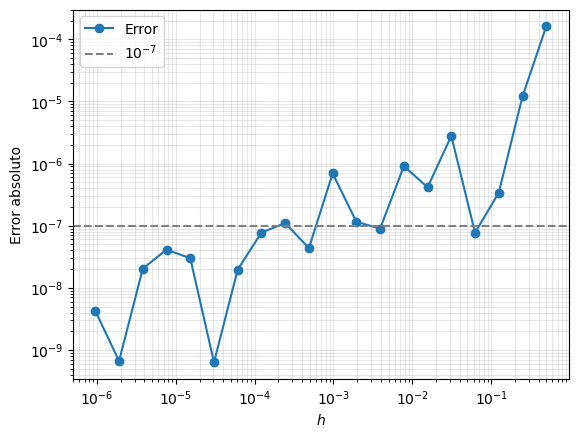

In [8]:
import numpy as np
import matplotlib.pyplot as plt

sigma = 1e-5
exacto = 1 - np.cos(1.0)
rng = np.random.default_rng(2026)

def p(x):
    return np.sin(x) + rng.normal(0, sigma, size=np.shape(x))

def simpson(f, a, b, N):
    x = np.linspace (a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

Ns = 2**np.arange(1,21)
hs = 1 / Ns
error = np.array ([abs(simpson(p, 0, 1, N) - exacto) for N in Ns]) 

for h, e in zip(hs, error):
    print(f"h = {h: .2e} error = {e: .2e}")

plt.loglog(hs, error, 'o-', label='Error')
plt.axhline(1e-7, color='gray', ls= '--', label= r'$10^{-7}$')
plt.xlabel('$h$')
plt.ylabel('Error absoluto')
plt.legend()
plt.grid(True, which= 'both', alpha=0.3)
plt.show()


### Conclusión

En conclusión, no se puede lograr una precisión de $10^{-7}$ de forma práctica. Para $h$ grandes el error disminuye como $h^4$, que es lo esperado para Simpson. Pero cerca de $h \approx 0.1$ el error deja de bajar rápido, porque desde ahí lo domina el ruido de las mediciones y no el método. 

El error debido al ruido es $\sum_i w_i n_i$, una suma de gaussianas independientes con los pesos de Simpson $w_i$. 

Por otro lado, su desviación estándar es

$$\sigma\sqrt{\sum_i w_i^2} \approx \sigma\sqrt{\frac{10\,h}{9}} \approx 10^{-5}\sqrt{h}.$$

Este error solo decrece como $\sqrt{h}$. Para que llegue a $10^{-7}$ se necesita $h \sim 10^{-4}$, es decir, del orden de $10^4$ mediciones, y aun así el resultado es aleatorio y puede quedar por encima de $10^{-7}$ (en el gráfico el error oscila alrededor de esa línea hasta $h \sim 10^{-5}$). Sin ruido bastarían unos $20$ puntos. Entonces la precisión queda limitada por el ruido experimental, no por el método de integración.